# Adiabatic QeMCMC

Here we introduce an approach to QeMCMC which includes an "adiabatic dressing". See [Adiabatic dressing of quantum enhanced Markov chains](https://arxiv.org/pdf/2603.28076) for the details.

The basic idea of their approach is to change the time evolution that we implement on the quantum computer from a "quench" (time evolution under a time independent hamiltonian of the form $H = H_\text{prob} + \gamma H_\text{mix}$) to an evolution under a time dependent Hamiltonian, $H = H_\text{prob} + \gamma (t) H_\text{mix}$ where $\gamma (0) = 0 = \gamma (t_\text{max})$. For well behaved functions and for large $t$, this should return the system to the same basis state that you start in thanks to the adiabatic theorem. However for shorter times, one will see diabatic transitions, out of the ground state towards nearby energy levels - exactly what we want in QeMCMC.


## Imports

In [ ]:
from joblib import Parallel, delayed
from matplotlib import pyplot as plt

# This helps you build an example Ising model
from qemcmc.model import ModelMaker

# Internal imports from QeMCMC package
# sampler contains the classical and quantum enhanced MCMC sampler
from qemcmc.sampler import ClassicalProposal, AdiabaticProposal
from qemcmc.sampler.runners import MCMCRunner

# These are object useful to store the results of the MCMC simulation
from qemcmc.utils import plot_chains


import numpy as np



## Define model problem and algorithm parameters

In [2]:

# Define parameters
n = 6 # Number of spins in the system
reps = 5 # How many markov chains to produce
steps = 300 # Length of each markov chain
temp = 0.1 # Temperature of the system


# QeMCMC parameters
gamma = 2# Relative strength of mixer hamiltonian 
alpha = 2 # Time for adiabatic ramp
kappa = 3 # time for plateaux
# Build an Ising model to test the algorithms on
model_type = "Fully Connected Ising"
name = "Test Ising model"
model = ModelMaker(n, model_type, name).model
initial_states = model.initial_state


## Run classical MCMC

In [3]:

runner = MCMCRunner(model, temp)


# Run classical (uniform and local) chains

uni_chains = []
for rep in range(reps):
    classical_uniform_proposal = ClassicalProposal(model=model, method = "uniform")
    uni_chain = runner.run(classical_uniform_proposal, steps, initial_state = initial_states[rep], name = "classical uniform MCMC", verbose = False, sample_frequency = 1)
    uni_chains.append(uni_chain)


loc_chains = []
for rep in range(reps):
    classical_local_proposal = ClassicalProposal(model=model, method = "local")
    loc_chain = runner.run(classical_local_proposal, steps, initial_state = initial_states[rep], name = "classical local MCMC", verbose = False, sample_frequency = 1)
    loc_chains.append(loc_chain)




## Run adiabatic MCMC

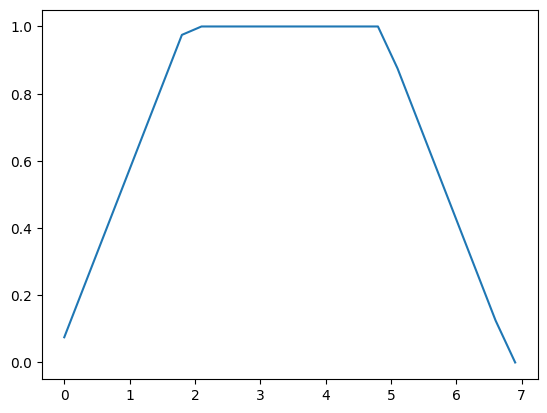

In [4]:
quantum_proposal = AdiabaticProposal(model, gamma=gamma, alpha=alpha, kappa = kappa, delta_t = 0.3)


# plot the schedule
dt = 0.3
h_list = []
times = np.arange(0, 2*alpha +kappa, dt)
for step, t_start in enumerate(times):
    t_mid = (step + 0.5) * dt
    h = quantum_proposal.CM.linear_schedule(t_mid, alpha, kappa)
    h_list.append(h)
plt.plot(times, h_list)



    

In [5]:
# run the algorithm
qsteps = 100


def run_qemcmc(rep):
    return runner.run(quantum_proposal, qsteps, initial_state=initial_states[rep], name="QeMCMC", verbose=True, sample_frequency=1)

# Run in parallel as they can take a while.
adi_chains = Parallel(n_jobs=-1)(delayed(run_qemcmc)(rep) for rep in range(reps))

#adi_chains = [run_qemcmc(1)]

## Analysis

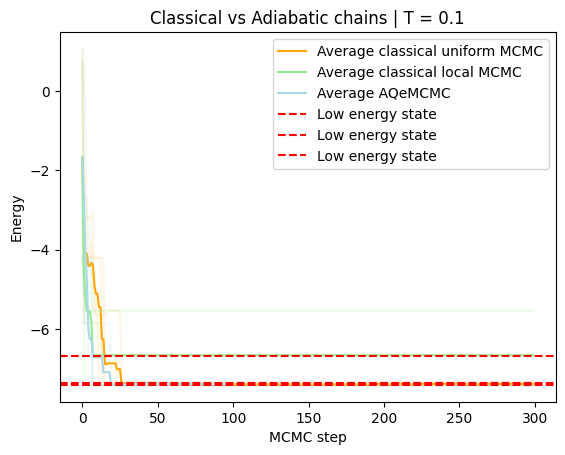

In [6]:
# Plot the list of chains with a helper function
# Dark line is for average ove rchains, transparent lines are for each individual chains

plot_chains(uni_chains, "orange", "classical uniform MCMC")
plot_chains(loc_chains, "lightgreen", "classical local MCMC")
plot_chains(adi_chains, "lightblue", "AQeMCMC")

lowest_energies, degeneracies, lowest_configs = model.get_lowest_energies(3, return_configurations=True)
for i, energy in enumerate(lowest_energies):
    if i<3:
        plt.axhline(energy, color="red", linestyle="--", label=f"Low energy state")

plt.xlabel("MCMC step")
plt.ylabel("Energy")
plt.title("Classical vs Adiabatic chains | T = {}".format(temp))
plt.legend()
plt.show()

# Make hamming energy graphs


In [7]:
import tqdm
n_spins = n
# (Classically) calculate energies of all configurations
all_energies = model.get_all_energies()


# (Classically) calculate the energy differences for all pairs of configurations
# And the Hamming distances for all pairs of configurations
S = np.array([np.binary_repr(s, width=n_spins) for s in range(2**n_spins)])
S_integer_arr = np.array([[int(bit) for bit in state] for state in S])
E_s = np.array(all_energies)

# find matrices of Energy differences of the configyurations, and hamming distances
E_diffs = np.zeros((2**n_spins, 2**n_spins))
hamming_dists = np.zeros((2**n_spins, 2**n_spins))
for s in S:
    for s_prime in S:
        hamming_dist = np.sum(np.bitwise_xor(S_integer_arr[int(s, 2)], S_integer_arr[int(s_prime, 2)]))
        E_diff = abs(E_s[int(s, 2)] - E_s[int(s_prime, 2)])
        E_diffs[int(s, 2), int(s_prime, 2)] = E_diff
        hamming_dists[int(s, 2), int(s_prime, 2)] = hamming_dist

E_order = np.argsort(E_s)



100%|██████████| 64/64 [00:00<00:00, 71.83it/s]


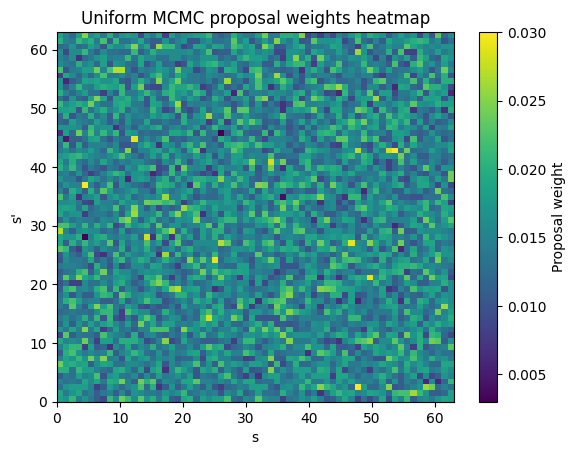

In [8]:
# How many times to sample each proposal
reps = 1000

uniform_proposal = ClassicalProposal(model,method = "uniform")
uniform_weights = np.zeros_like(E_diffs)
self_proposals = 0
for i, s in enumerate(tqdm.tqdm(S)):
    for j in range(reps):
        state = uniform_proposal.update(s)
        state_int = int(state, 2)
        uniform_weights[i, state_int] += 1
uniform_weights = uniform_weights / (reps)
uniform_weights_ordered = uniform_weights[E_order, :][:, E_order]




plt.hist2d(np.repeat(np.arange(2**n_spins), 2**n_spins), np.tile(np.arange(2**n_spins), 2**n_spins), bins=2**n_spins, weights=uniform_weights_ordered.flatten())#, norm="log")
plt.title("Uniform MCMC proposal weights heatmap")
plt.xlabel("s")
plt.ylabel("s'")
plt.colorbar(label="Proposal weight")
plt.show()



100%|██████████| 64/64 [00:00<00:00, 175.60it/s]


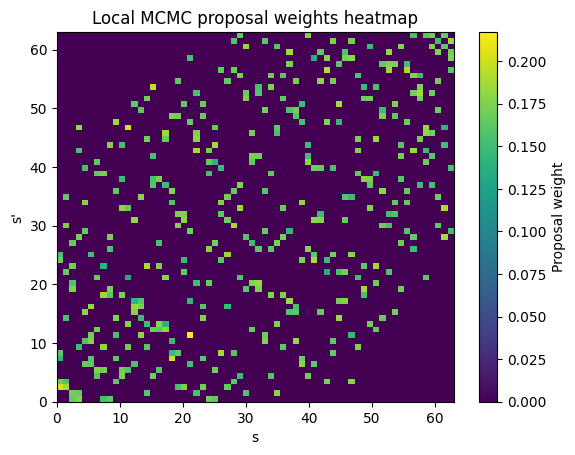

In [9]:
# How many times to sample each proposal
reps = 1000
local_proposal = ClassicalProposal(model, method = "local")
local_weights = np.zeros_like(E_diffs)
self_proposals = 0
for i, s in enumerate(tqdm.tqdm(S)):
    for j in range(reps):
        state = local_proposal.update(s)
        state_int = int(state, 2)
        local_weights[i, state_int] += 1
local_weights = local_weights / (reps)
local_weights_ordered = local_weights[E_order, :][:, E_order]




plt.hist2d(np.repeat(np.arange(2**n_spins), 2**n_spins), np.tile(np.arange(2**n_spins), 2**n_spins), bins=2**n_spins, weights=local_weights_ordered.flatten())#, norm="log")
plt.title("Local MCMC proposal weights heatmap")
plt.xlabel("s")
plt.ylabel("s'")
plt.colorbar(label="Proposal weight")
plt.show()



100%|██████████| 64/64 [00:05<00:00, 11.77it/s]


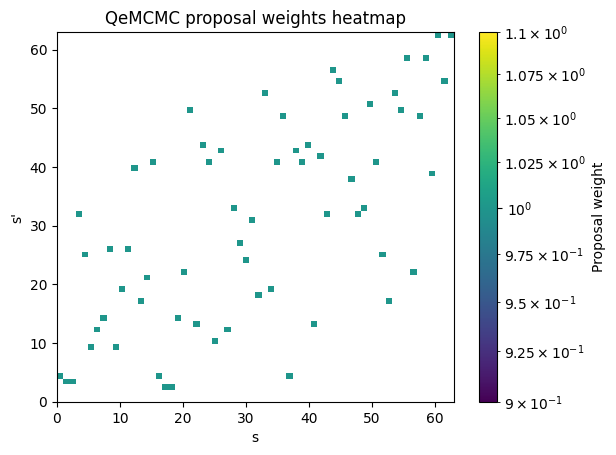

100%|██████████| 64/64 [00:05<00:00, 12.76it/s]


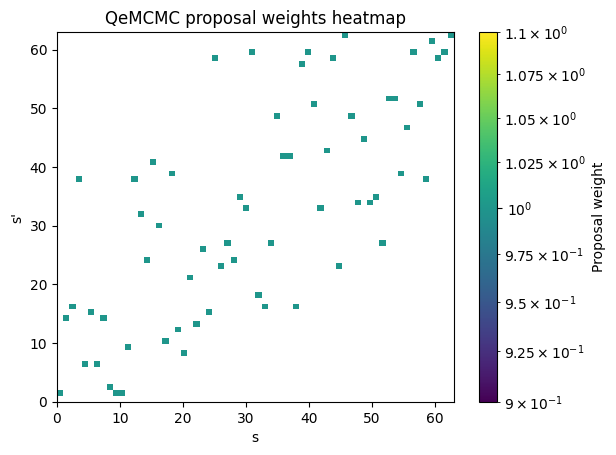

100%|██████████| 64/64 [00:05<00:00, 10.82it/s]


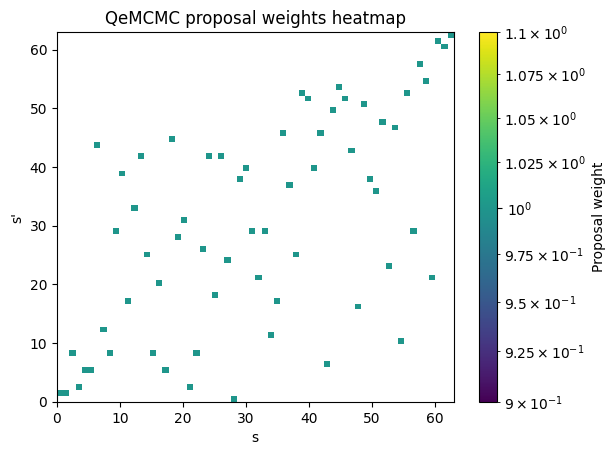

100%|██████████| 64/64 [00:05<00:00, 12.68it/s]


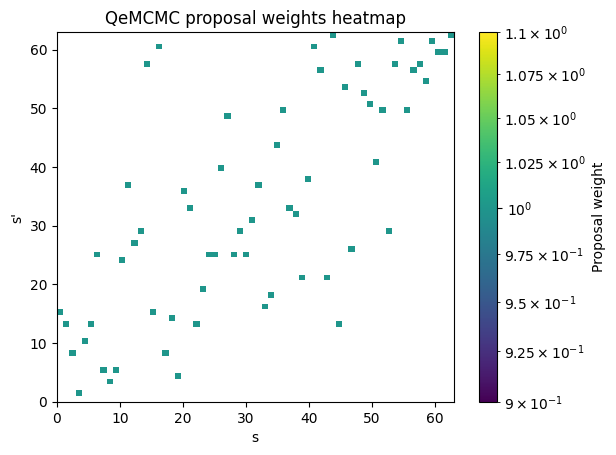

In [10]:
def brute_force_quantum(qp):
    # brute force method to get QeMCMC weights
    qemcmc_weights_brute = np.zeros_like(E_diffs)
    reps = 1
    for i, s in enumerate(tqdm.tqdm(S)):
        for j in range(reps):
            state = qp.update(s)
            state_int = int(state, 2)
            qemcmc_weights_brute[i, state_int] += 1
    qemcmc_weights_brute = qemcmc_weights_brute / (reps)

    qemcmc_weights_brute_ordered = qemcmc_weights_brute[E_order, :][:, E_order]
    # make the color graident logarithmic
    plt.hist2d(np.repeat(np.arange(2**n_spins), 2**n_spins), np.tile(np.arange(2**n_spins), 2**n_spins), bins=2**n_spins, weights=qemcmc_weights_brute_ordered.flatten(), norm="log")
    plt.title("QeMCMC proposal weights heatmap")
    plt.xlabel("s")
    plt.ylabel("s'")
    plt.colorbar(label="Proposal weight")
    plt.show()
    row_sums_brute = qemcmc_weights_brute.sum(axis=1)
    qemcmc_weights_brute = qemcmc_weights_brute / row_sums_brute[:, np.newaxis]
    return qemcmc_weights_brute

adi_weights_brute = []
adi_labels = []
quantum_proposal = AdiabaticProposal(model, gamma=gamma, alpha=alpha, kappa = kappa, delta_t = 0.3)
adi_weights_brute.append(brute_force_quantum(quantum_proposal))
adi_labels.append("adiabatic")

quantum_proposal_k = AdiabaticProposal(model, gamma=2, alpha=2, kappa = (0,10), delta_t = 0.3)
adi_weights_brute.append(brute_force_quantum(quantum_proposal))
adi_labels.append("kappa (0,10)")

quantum_proposal_g = AdiabaticProposal(model, gamma=(2,3), alpha=2, kappa = (0,10), delta_t = 0.3)
adi_weights_brute.append(brute_force_quantum(quantum_proposal))
adi_labels.append("gamma (2,3), kappa (0,10)")

quantum_proposal_a = AdiabaticProposal(model, gamma=(2,3), alpha=(2,3), kappa = (0,10), delta_t = 0.3)
adi_weights_brute.append(brute_force_quantum(quantum_proposal))
adi_labels.append("alpha (2,3), gamma (2,3), kappa (0,10)")



  0%|          | 0/64 [00:00<?, ?it/s]

100%|██████████| 64/64 [00:04<00:00, 13.81it/s]


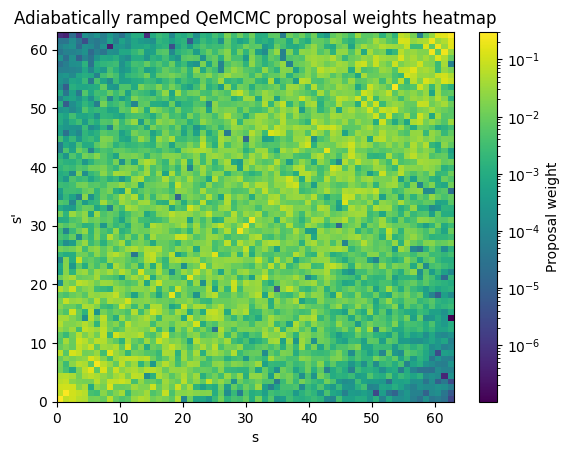

In [11]:

time = 10
qemcmc_weights = np.zeros_like(E_diffs)
for i, s in enumerate(tqdm.tqdm(S)):
    probabilities = np.abs(quantum_proposal.CM.get_state_vector(s, alpha, kappa, gamma, np.ones(len(quantum_proposal.coupling_weights)), 0.3)) ** 2
    qemcmc_weights[int(i),:] += probabilities


qemcmc_weights_ordered = qemcmc_weights[E_order, :][:, E_order]


plt.hist2d(np.repeat(np.arange(2**n_spins), 2**n_spins), np.tile(np.arange(2**n_spins), 2**n_spins), bins=2**n_spins, weights=qemcmc_weights_ordered.flatten(), norm="log")
plt.title("Adiabatically ramped QeMCMC proposal weights heatmap")
plt.xlabel("s")
plt.ylabel("s'")
plt.colorbar(label="Proposal weight")
# plt.show()
self_proposals_percent = (100 * np.sum(np.diag(qemcmc_weights))) / (reps * (2**n_spins))

# normalise
row_sums = qemcmc_weights.sum(axis=1)
qemcmc_weights = qemcmc_weights / row_sums[:, np.newaxis]


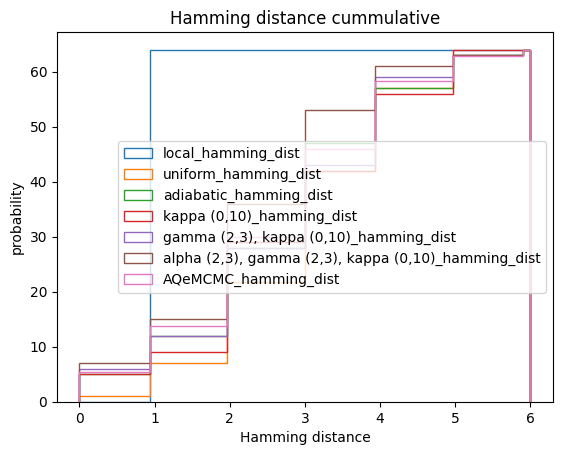

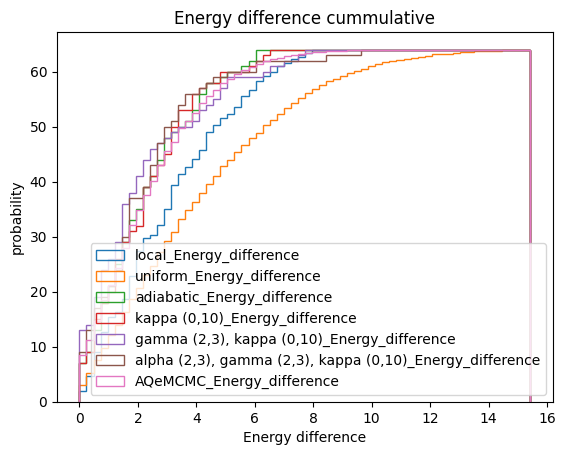

In [12]:




# plot histograms of hamming distances
weights_list = [local_weights, uniform_weights]+ adi_weights_brute + [qemcmc_weights]
labels = ["local", "uniform"]+adi_labels+["AQeMCMC"]
for weights, label in zip(weights_list, labels):
    plt.hist(hamming_dists.flatten(), bins=2**n_spins, weights=weights.flatten(), density=False, histtype="step", cumulative=True, label=label + "_hamming_dist")
    # plt.hist(E_diffs.flatten(), bins = n_spins, weights = weights.flatten(), density=True, histtype="step",
    #         cumulative=True, label=label+"_Energy_difference")
plt.legend()
plt.title("Hamming distance cummulative")
plt.xlabel("Hamming distance")
plt.ylabel("probability")
plt.show()



# plot energy difference histograms 
for weights, label in zip(weights_list, labels):
    plt.hist(E_diffs.flatten(), bins=2 ** (n_spins), weights=weights.flatten(), density=False, histtype="step", cumulative=True, label=label + "_Energy_difference")
plt.legend()
plt.title("Energy difference cummulative")
plt.xlabel("Energy difference")
plt.ylabel("probability")
plt.show()